# F4 · Gene sets (Fig 4)

**Run first:** `R3_gene_set.ipynb` (`results/gene_set/`) and `R4_timing.ipynb` (`results/timing/gene_set.csv`).

Panels, saved to `figures/fig4_gene_set/panels/` (PDF + 1200-dpi PNG), then the full figure `figures/fig4_gene_set/fig4_gene_set.{pdf,png}`:
* **A** the typical breast query (|S| = 16): the exact d_B^S of every index tile (grey) and of the tiles Spindle returned
* **B** NX at 5 % of N against |S|: Spindle, padding + Spindle-naive, imputation + Spindle-naive
  (median over datasets, mean ± s.d. over seeds)
* **C** Overlap(5 %, 5 % of N) against |S|, the same methods
* **D** time per query, search only: Spindle-naive (its scan without the query logs it computes inside) and Spindle;
  bars show the mean over seeds of the per-seed median, whiskers the s.d.; each index's query logs are open markers; the speed-up is search only
* **E** Spindle NX at 5 % of N per dataset, all sizes pooled (mean ± s.d. over seeds)
* **F** stored MB per dataset: whole covariances, Spindle-naive, Spindle, padding, imputation

Light (seconds); runs on the login node (Liberation Sans).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib import patheffects
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory

import gene_set_accuracy as gsa
import style as ps

FIG = "fig4_gene_set"
RES = ps.ROOT / "results" / "gene_set"
KEYS = ps.DATASET_ORDER
SPINDLE, NAIVE, WHOLE = ps.TIER_COLORS["spindle_partial"], ps.TIER_COLORS["naive"], ps.TIER_COLORS["whole"]
BASE = {"padding": "#44AA99", "imputation": "#882255"}
METHOD_LABEL = {"spindle_partial": "Spindle", "padding": "Padding + Spindle-naive",
                "imputation": "Imputation + Spindle-naive"}
MARK = {"spindle_partial": "^", "padding": "s", "imputation": "o"}
COLOR = {"spindle_partial": SPINDLE, **BASE}
TOP_H, ROW_H = 50.0, 66.0          # panel heights (mm): row 1, row 2
TOP_IN = 5.5                       # mm above the axes (panel letter, title)
BOTTOM = 9.0

band = np.load(RES / "band" / "breast_cancer.npz")
nx_size = pd.read_csv(RES / "nx_size.csv")
nx = pd.read_csv(RES / "nx.csv")
storage = pd.read_csv(RES / "storage.csv").set_index("key")
_, _, timing = gsa.timing_tables(pd.read_csv(ps.ROOT / "results" / "timing" / "gene_set.csv"))
timing = timing.set_index("key")
timing[["naive_partial_search_ms", "spindle_partial_ms", "qlog_naive_partial_ms", "qlog_spindle_partial_ms",
        "speedup_spindle_partial", "speedup_e2e"]].round(3)


def rows_axis(ax, labels):
    ax.set_ylim(len(KEYS) - 0.5, -0.5)
    ax.set_yticks(range(len(KEYS)))
    ax.set_yticklabels([ps.DATASET_LABELS[k] for k in KEYS] if labels else [])
    ax.tick_params(axis="y", length=0)


def legend(fig, handles, ncol, top=False):
    """A legend along the bottom of a panel, or along the top of a legend strip of the page."""
    fig.legend(handles=handles, ncol=ncol, loc="upper center" if top else "lower center",
               bbox_to_anchor=(0.5, 1.0 if top else 0.0), frameon=False)

## A · the typical breast query

figures/fig4_gene_set/panels/A.pdf/.png: 60 x 50 mm, 0.0 / 0.2 MB


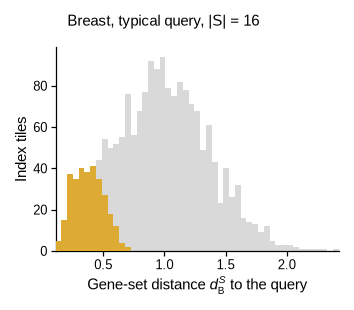

In [2]:
def panel_a(fig):
    ax = ps.axes(fig, left=10.0, right=2.0, bottom=BOTTOM, top=TOP_IN + 1.0)
    d, found = band["d"], band["found"]
    bins = np.linspace(d.min(), np.quantile(d, 0.995), 50)
    ax.hist(d, bins=bins, color=ps.LIGHT, lw=0, zorder=2)
    ax.hist(d[found], bins=bins, color=SPINDLE, lw=0, zorder=3)
    ax.set_xlabel(r"Gene-set distance $d^{S}_{\mathcal{B}}$ to the query")
    ax.set_ylabel("Index tiles")
    ax.set_xlim(bins[0], bins[-1])
    w, h = ps.size_mm(fig)
    fig.text(12 / w, 1 - 1.0 / h, "Breast, typical query, |S| = 16", ha="left", va="top")


fig = ps.panel(60, TOP_H)
panel_a(fig)
ps.save_panel(fig, FIG, "A")

## B, C · NX and Overlap against |S|

figures/fig4_gene_set/panels/B.pdf/.png: 58 x 62 mm, 0.0 / 0.2 MB
figures/fig4_gene_set/panels/C.pdf/.png: 58 x 62 mm, 0.0 / 0.2 MB


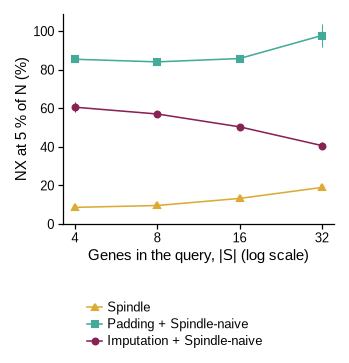

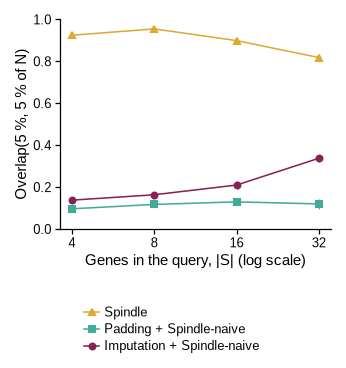

In [3]:
NX_HANDLES = [Line2D([], [], marker=MARK[m], ms=2.8, color=COLOR[m], label=METHOD_LABEL[m])
              for m in ("spindle_partial", "padding", "imputation")]


def by_size(fig, col, scale, ylabel, ylim, leg):
    bottom = BOTTOM + (12.0 if leg else 0.0)
    ax = ps.axes(fig, left=10.0, right=2.0, bottom=bottom, top=TOP_IN)
    t = nx_size[nx_size["size"] > 0]
    for m in ("padding", "imputation", "spindle_partial"):
        s = t[t.method == m].sort_values("size")
        ax.errorbar(s["size"], scale * s[col], yerr=scale * s[f"{col}_sd"], fmt=f"-{MARK[m]}", ms=2.8,
                    color=COLOR[m], elinewidth=0.5, zorder=3 if m == "spindle_partial" else 2)
    ax.set_xscale("log", base=2)
    ax.set_xticks([4, 8, 16, 32], ["4", "8", "16", "32"])
    ax.minorticks_off()
    ax.set_ylim(*ylim)
    ax.set_xlabel("Genes in the query, |S| (log scale)")
    ax.set_ylabel(ylabel)
    if leg:
        legend(fig, NX_HANDLES, 1)


def panel_b(fig, leg=True):
    by_size(fig, "NX5", 100, "NX at 5 % of N (%)", (0, None), leg)


def panel_c(fig, leg=True):
    by_size(fig, "overlap5", 1, "Overlap(5 %, 5 % of N)", (0, 1.0), leg)


fig = ps.panel(58, TOP_H + 12)
panel_b(fig)
ps.save_panel(fig, FIG, "B")
fig = ps.panel(58, TOP_H + 12)
panel_c(fig)
ps.save_panel(fig, FIG, "C")

## D · time per query (search only) and the speed-up

figures/fig4_gene_set/panels/D.pdf/.png: 68 x 75 mm, 0.0 / 0.3 MB


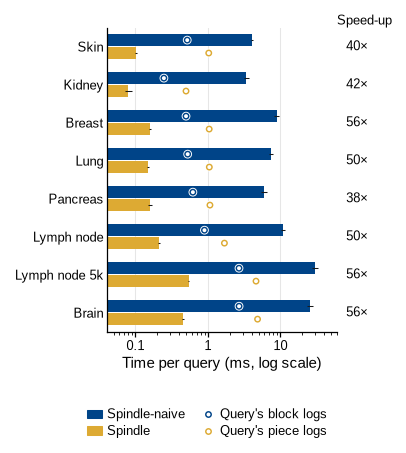

In [4]:
HALO = [patheffects.withStroke(linewidth=1.6, foreground="white")]  # query-log markers stay visible on a bar
TIME_HANDLES = [Patch(color=NAIVE, label="Spindle-naive"), Patch(color=SPINDLE, label="Spindle"),
                Line2D([], [], ls="", marker="o", ms=2.6, mfc="white", mec=NAIVE, mew=0.7, label="Query's block logs"),
                Line2D([], [], ls="", marker="o", ms=2.6, mfc="white", mec=SPINDLE, mew=0.7, label="Query's piece logs")]


def panel_d(fig, leg=True):
    bottom = BOTTOM + (9.0 if leg else 0.0)
    ax = ps.axes(fig, left=17.0, right=12.0, bottom=bottom, top=TOP_IN)
    t = timing
    bh = 0.34
    for i, k in enumerate(KEYS):
        r = t.loc[k]
        for off, col, qcol, c in ((-bh / 2, "naive_partial_search_ms", "qlog_naive_partial_ms", NAIVE),
                                  (bh / 2, "spindle_partial_ms", "qlog_spindle_partial_ms", SPINDLE)):
            ax.barh(i + off, r[col], height=bh * 0.92, color=c, lw=0, zorder=2)
            ax.errorbar(r[col], i + off, xerr=r[f"{col}_sd"], fmt="none", ecolor=ps.INK, elinewidth=0.5, zorder=3)
            ax.plot(r[qcol], i + off, "o", ms=2.6, mfc="white", mec=c, mew=0.7, zorder=4, path_effects=HALO)
    ax.set_xscale("log")
    ps.plain_log(ax, "x", subs=(1.0,))
    ps.log_grid(ax, "x")
    lo = min(t.spindle_partial_ms.min(), t.qlog_spindle_partial_ms.min(), t.qlog_naive_partial_ms.min()) / 2
    hi = max(t.naive_partial_search_ms.max(), t.qlog_naive_partial_ms.max(), t.qlog_spindle_partial_ms.max()) * 2
    ax.set_xlim(lo, hi)
    rows_axis(ax, True)
    ax.set_xlabel("Time per query (ms, log scale)")
    tr = blended_transform_factory(ax.transAxes, ax.transData)
    for i, k in enumerate(KEYS):
        ax.text(1.04, i, f"{t.loc[k].speedup_spindle_partial:.0f}×", transform=tr, ha="left", va="center",
                fontsize=ps.TICK_PT, clip_on=False)
    ax.text(1.0, 1.0, "Speed-up", transform=ax.transAxes, ha="left", va="bottom", fontsize=ps.TICK_PT)
    if leg:
        legend(fig, TIME_HANDLES, 2)


fig = ps.panel(68, ROW_H + 9)
panel_d(fig)
ps.save_panel(fig, FIG, "D")

## E · Spindle NX per dataset

figures/fig4_gene_set/panels/E.pdf/.png: 44 x 66 mm, 0.0 / 0.1 MB


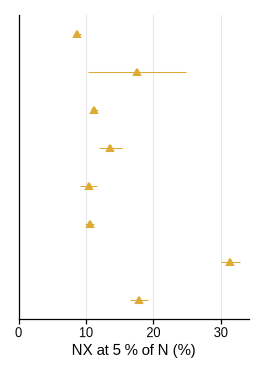

In [5]:
def panel_e(fig):
    t = nx[(nx.method == "spindle_partial") & (nx["size"] == 0)].set_index("key")
    ax = ps.axes(fig, left=2.0, right=3.0, bottom=BOTTOM, top=TOP_IN)
    for i, k in enumerate(KEYS):
        r = t.loc[k]
        ax.errorbar(100 * r.NX5, i, xerr=100 * r.NX5_sd, fmt="^", ms=3.0, color=SPINDLE, elinewidth=0.5, zorder=3)
    rows_axis(ax, False)
    ax.set_xlim(0, None)
    ax.grid(True, axis="x", color="#E6E6E6", linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.set_xlabel("NX at 5 % of N (%)")


fig = ps.panel(44, ROW_H)
panel_e(fig)
ps.save_panel(fig, FIG, "E")

## F · storage

figures/fig4_gene_set/panels/F.pdf/.png: 56 x 86 mm, 0.0 / 0.2 MB


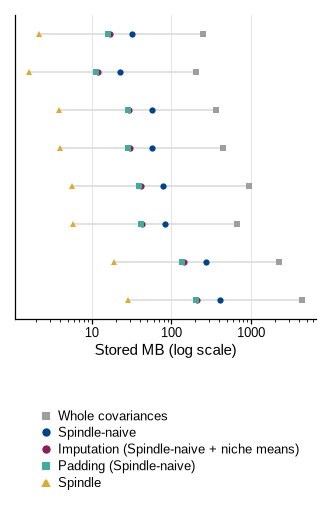

In [6]:
STORE = [("whole", WHOLE, "s"), ("naive_partial", NAIVE, "o"), ("imputation", BASE["imputation"], "o"),
         ("padding", BASE["padding"], "s"), ("spindle_partial", SPINDLE, "^")]
STORE_LABEL = {"whole": "Whole covariances", "naive_partial": "Spindle-naive",
               "imputation": "Imputation (Spindle-naive + niche means)", "padding": "Padding (Spindle-naive)",
               "spindle_partial": "Spindle"}
STORE_HANDLES = [Line2D([], [], ls="", marker=mk, ms=3.0, color=c, label=STORE_LABEL[col]) for col, c, mk in STORE]


def panel_f(fig, leg=True):
    bottom = BOTTOM + (20.0 if leg else 0.0)
    ax = ps.axes(fig, left=2.0, right=3.0, bottom=bottom, top=TOP_IN)
    t = storage
    for i, k in enumerate(KEYS):
        r = t.loc[k]
        ax.plot([r.spindle_partial, r.whole], [i, i], color=ps.LIGHT, lw=0.75, zorder=1)
        for col, c, mk in STORE:
            ax.plot(r[col], i, mk, ms=3.0 if mk != "^" else 3.3, color=c, mew=0,
                    zorder=3 if col == "spindle_partial" else 2)
    ax.set_xscale("log")
    ps.plain_log(ax, "x", subs=(1.0,))
    ps.log_grid(ax, "x")
    rows_axis(ax, False)
    ax.set_xlabel("Stored MB (log scale)")
    if leg:
        legend(fig, STORE_HANDLES, 1)


fig = ps.panel(56, ROW_H + 20)
panel_f(fig)
ps.save_panel(fig, FIG, "F")

## Full figure

figures/fig4_gene_set/fig4_gene_set.pdf/.png: 180 x 132 mm, 0.0 / 1.2 MB


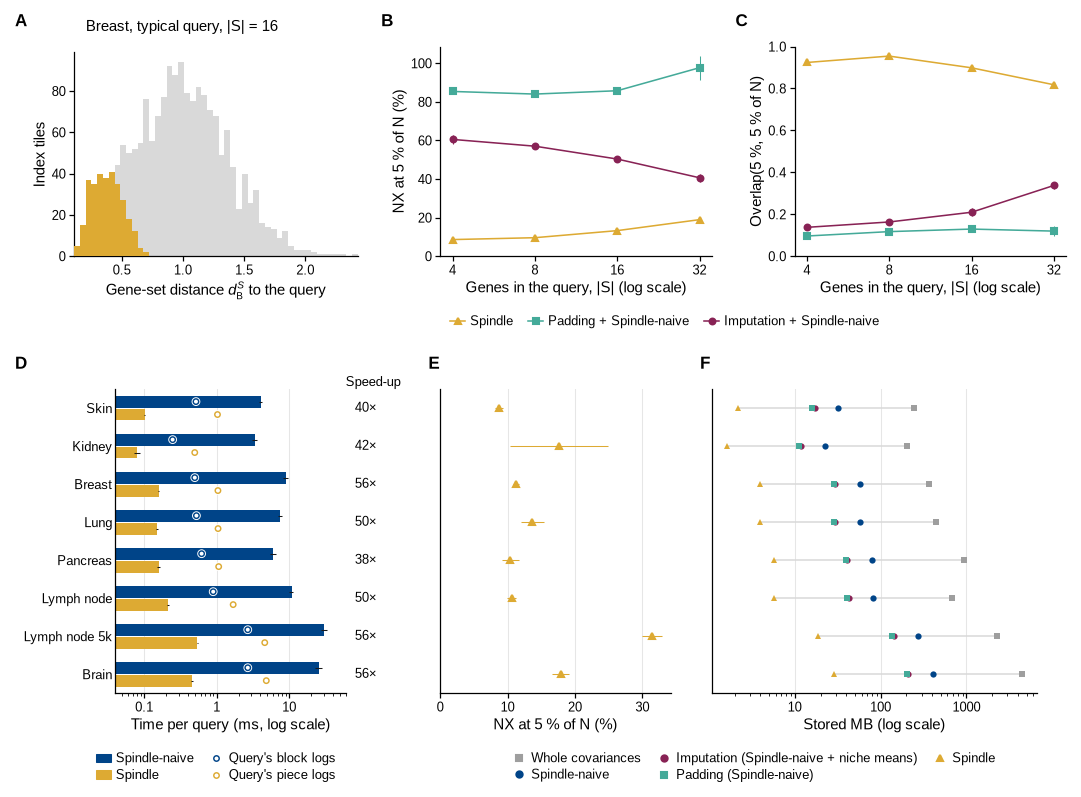

In [7]:
page = ps.page(180, 132)
panel_a(ps.place(page, "A", 0, 0, 60, TOP_H))
panel_b(ps.place(page, "B", 62, 0, 58, TOP_H), leg=False)
panel_c(ps.place(page, "C", 122, 0, 58, TOP_H), leg=False)
legend(ps.place(page, None, 40, TOP_H + 1, 140, 6), NX_HANDLES, 3, top=True)
panel_d(ps.place(page, "D", 0, 58, 68, ROW_H), leg=False)
panel_e(ps.place(page, "E", 70, 58, 44, ROW_H))
panel_f(ps.place(page, "F", 116, 58, 60, ROW_H), leg=False)
legend(ps.place(page, None, 0, 59 + ROW_H, 68, 7), TIME_HANDLES, 2, top=True)
legend(ps.place(page, None, 70, 59 + ROW_H, 110, 7), STORE_HANDLES, 3, top=True)
ps.save_figure(page, FIG)